# Notebook 10: Merged-Flood Operational Taxonomy Evaluation on CICIoT2023 (`OP29` vs. `ORIG34`)

> **Scope & Design Integrity**: Strictly read-only post-hoc taxonomy evaluation using Track 1's verified zero-overlap Strategy 1 Internal Test partition (`N = 75,105`) and Track 2's frozen **E4** classifier ([`e4_lgbm_leaves63_sqrt.joblib`](../track2_ids_engineering/hierarchical_ids/models/e4_lgbm_leaves63_sqrt.joblib)). Zero retraining, zero new splits, zero test-set tuning, and zero alterations to Track 1 or historical result files.


In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

plt.rcParams["figure.dpi"] = 130
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.28
plt.rcParams["grid.linestyle"] = "--"

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

RESULTS_DIR = REPO_ROOT / "track2_ids_engineering" / "hierarchical_ids" / "results"
CM_DIR = RESULTS_DIR / "confusion_matrices"
RAW_MERGED01 = REPO_ROOT / "data" / "raw" / "Merged01.csv"

assert RESULTS_DIR.exists(), f"Missing results dir: {RESULTS_DIR}"

import track1_dataset_evaluation.src as _t1_compat  # noqa: F401
from track1_dataset_evaluation.src.config import (
    FEATURE_COLUMNS,
    LABEL_MAPPING_8CLASSES,
    ORIGINAL_SAMPLE_FILE,
    PARTITION_ASSIGNMENTS_FILE,
    TARGET_COLUMN,
    THIRTY_FOUR_CLASSES,
    THIRTY_FOUR_TO_IDX,
)
from track1_dataset_evaluation.src.evaluate import evaluate_predictions_v2
from track2_ids_engineering.hierarchical_ids.src.data_utils import (
    FLOOD_CATEGORIES,
    FLOOD_CLASSES,
    HIER_MODELS_DIR,
    NON_FLOOD_CLASSES,
    load_track1_splits,
)
from track2_ids_engineering.hierarchical_ids.experiments.run_presentation_updates import (
    OP29_MERGE_GROUPS,
    OP30_MERGE_GROUPS,
    build_operational_mapping,
)

print(f"Repository Root : {REPO_ROOT}")
print(f"Results Folder  : {RESULTS_DIR}")
print(f"Canonical Schema: {len(FEATURE_COLUMNS)} numerical features | {len(THIRTY_FOUR_CLASSES)} classes")


Repository Root : C:\Users\priya\Downloads\capstone
Results Folder  : C:\Users\priya\Downloads\capstone\track2_ids_engineering\hierarchical_ids\results
Canonical Schema: 39 numerical features | 34 classes


## Section 1: Introduction and Motivation

### 1.1 The Standard CICIoT2023 34-Class Classification Task
In CICIoT2023, fine-grained intrusion detection is standardized as a **34-class supervised problem**:
- **1 Benign class**: `BENIGN`
- **16 Volumetric Flood classes**: `12 DDoS` variants and `4 DoS` variants
- **17 Non-Flood classes**: `3 Mirai`, `5 Recon`, `2 Spoofing`, `6 Web`, and `1 BruteForce`

Across Track 1 and Track 2 (`E1–E4`), our top recommended classifier **E4 (`E4_LGBM_Leaves63_Sqrt`)** reaches **75.37% Accuracy (`0.63523` Macro-F1, `0.74402` MCC)** on the leak-free Strategy 1 Internal Test split (`N = 75,105`). Yet nearly half of E4's misclassifications happen *inside* just four protocol families (`SYN`, `TCP`, `UDP`, `HTTP`) rather than across distinct security threats.

### 1.2 Why DoS vs. DDoS Distinction Matters—And Why 39 Flow Features Cannot Support It
In operational incident response and forensics, distinguishing **Denial of Service (DoS)** from **Distributed Denial of Service (DDoS)** matters:
- **Source scope & response escalation**: DoS originates from one or very few misbehaving endpoints (making targeted host quarantine or single-source IP blocking effective), whereas DDoS reflects coordinated multi-host traffic that often demands upstream scrubbing or BGP FlowSpec filtering.
- **Forensic attribution**: Identifying multi-host botnet involvement helps assess lateral spread vs. localized misconfiguration.

However, tabular CICIoT2023 CSV files record **summary packet/flow statistics (`39` features)** computed per flow window **without any host-identifying keys**: there are **no source IP addresses, destination IP addresses, TCP/UDP port numbers, timestamps, or distinct source-IP counts**. When one attacker or 100 coordinated bots emit pure TCP SYN floods (`syn_flag_number = 1.0`, `Tot size = 60`), their individual flow feature vectors overlap or collide identically in the 39-dimensional space.

### 1.3 Operational Usefulness vs. Academic Classification Accuracy
This exposes an important distinction:
- **34-class Accuracy** measures exact match against CICIoT2023's lab-recorded attack taxonomy, including DoS vs. DDoS splits that depend on unrecorded testbed host counts.
- **Operational Usefulness** asks whether the IDS identifies the **correct transport/application protocol flood family** so downstream security policy selects an appropriate **protocol-level mitigation action** instead of emitting unstable, arbitrarily flipped `DoS` vs. `DDoS` guesses.

Because merging ambiguous labels changes the prediction target itself, **accuracy under an operational taxonomy (`OP29`) and accuracy under the original 34-class benchmark (`ORIG34`) solve different tasks and must never be conflated**.


## Section 2: Dataset and Feature Limitations

In this section, we inspect the actual recorded feature schema, the Strategy 1 Internal Test class distribution (`N = 75,105`), and the quantitative audit of exact feature collisions from [`merged_flood_twin_group_audit.csv`](../track2_ids_engineering/hierarchical_ids/results/merged_flood_twin_group_audit.csv).

**Precision on Feature Availability**: CICIoT2023 *does* include valuable packet- and flow-level network telemetry across `39` numerical features—such as `Protocol Type`, `Header_Length`, TCP flags (`syn_flag_number`, `ack_flag_number`, `psh_flag_number`, `rst_flag_number`, `fin_flag_number`), flag counts, packet size summary statistics (`Min`, `Max`, `AVG`, `Std`, `Tot size`), `Rate`, and `IAT`. What it **precisely omits** in the exported tabular schema are **IP addresses (`src_ip`, `dst_ip`), transport ports (`src_port`, `dst_port`), capture timestamps, packet payloads, and multi-host cardinality/entropy indicators**.


In [2]:
# 1. Verify exact raw column schema when raw CSV is available locally
if RAW_MERGED01.exists():
    raw_cols = list(pd.read_csv(RAW_MERGED01, nrows=0).columns)
    assert len(raw_cols) == 40 and raw_cols[-1] == TARGET_COLUMN
    assert raw_cols[:-1] == FEATURE_COLUMNS
    print(f"Verified raw Merged01.csv schema: {len(raw_cols)} total columns (39 features + Label).")
else:
    print(f"Raw CSV omitted; verified canonical FEATURE_COLUMNS count = {len(FEATURE_COLUMNS)}.")

identifier_cols = [
    c for c in FEATURE_COLUMNS
    if any(tok in c.lower() for tok in ("src", "dst", "addr", "port", "host", "mac", "stamp", "flow_id"))
]
print("Host/IP-address/port/timestamp identifier columns in FEATURE_COLUMNS:", identifier_cols)
print("Note: 'IPv' is a binary IPv4 indicator (1/0) and 'Time_To_Live' is packet TTL (hops), NOT an IP address or timestamp.")
print("Sample present network telemetry features:", FEATURE_COLUMNS[:12])

# 2. Load Track 1 zero-overlap Strategy 1 splits (Train & Internal Test)
splits = load_track1_splits(include_test=True, include_cross_capture=False, verify_disjoint=True)
y_train_34 = splits["train"]["y_fine"]
y_val_34 = splits["val"]["y_fine"]
y_test_34 = splits["test"]["y_fine"]

assert len(y_train_34) == 350821
assert len(y_val_34) == 75172
assert len(y_test_34) == 75105

# Verify Internal Test support by class & functional role
test_counts = np.bincount(y_test_34, minlength=len(THIRTY_FOUR_CLASSES))
twin_member_set = {m for members in OP29_MERGE_GROUPS.values() for m in members}

dist_rows = []
for idx, cname in enumerate(THIRTY_FOUR_CLASSES):
    cat8 = LABEL_MAPPING_8CLASSES[cname]
    if cname == "BENIGN":
        role = "Benign"
    elif cname in twin_member_set:
        role = "Twin Flood (Merged in OP29)"
    elif cname in FLOOD_CLASSES:
        role = "Other Flood (Unmerged)"
    else:
        role = f"Non-Flood ({cat8})"
    dist_rows.append({
        "class": cname,
        "category_8": cat8,
        "role": role,
        "test_support": int(test_counts[idx]),
        "test_pct": round(100.0 * test_counts[idx] / len(y_test_34), 2),
    })

df_dist = pd.DataFrame(dist_rows).sort_values("test_support", ascending=True).reset_index(drop=True)
print(f"\nInternal Test N = {len(y_test_34):,} | Total Flood flows = {int(splits['test']['is_flood'].sum()):,} "
      f"({100.0 * splits['test']['is_flood'].mean():.2f}%) | Non-Flood = {int(splits['test']['is_non_flood'].sum()):,}")
display(df_dist.sort_values("test_support", ascending=False).head(15))


Verified raw Merged01.csv schema: 40 total columns (39 features + Label).
Host/IP-address/port/timestamp identifier columns in FEATURE_COLUMNS: []
Note: 'IPv' is a binary IPv4 indicator (1/0) and 'Time_To_Live' is packet TTL (hops), NOT an IP address or timestamp.
Sample present network telemetry features: ['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count']



Internal Test N = 75,105 | Total Flood flows = 40,511 (53.94%) | Non-Flood = 28,575


,class,category_8,role,test_support,test_pct
33,BENIGN,Benign,Benign,6019,8.01
32,MIRAI-GREIP_FLOOD,Mirai,Non-Flood (Mirai),3086,4.11
31,DNS_SPOOFING,Spoofing,Non-Flood (Spoofing),3037,4.04
30,DDOS-ICMP_FRAGMENTATION,DDoS,Other Flood (Unmerged),3017,4.02
29,DDOS-UDP_FRAGMENTATION,DDoS,Other Flood (Unmerged),3004,4.00
28,VULNERABILITYSCAN,Recon,Non-Flood (Recon),2994,3.99
26,DDOS-ACK_FRAGMENTATION,DDoS,Other Flood (Unmerged),2968,3.95
27,RECON-OSSCAN,Recon,Non-Flood (Recon),2968,3.95
25,MIRAI-GREETH_FLOOD,Mirai,Non-Flood (Mirai),2958,3.94
24,RECON-PORTSCAN,Recon,Non-Flood (Recon),2950,3.93


In [3]:
# Load verified twin-group audit evidence & inspect median raw SYN features in Train
df_audit = pd.read_csv(RESULTS_DIR / "merged_flood_twin_group_audit.csv")
print("Verified Twin-Group Feature Overlap & E4 Internal Test Swap Audit:")
display(df_audit)

# Check actual raw feature signatures across the 3 SYN twin variants in Train only
df_raw = pd.read_csv(ORIGINAL_SAMPLE_FILE)
df_assign = pd.read_csv(PARTITION_ASSIGNMENTS_FILE)
df_clean = df_raw.iloc[df_assign["orig_idx"]].copy().reset_index(drop=True)
df_clean["partition"] = df_assign["partition"].values
df_train_raw = df_clean[df_clean["partition"] == "train"].copy()
df_train_raw["LabelUpper"] = df_train_raw[TARGET_COLUMN].astype(str).str.strip().str.upper()

syn_inspect_cols = ["syn_flag_number", "syn_count", "ack_flag_number", "Protocol Type", "Rate", "Tot size", "Header_Length"]
syn_medians = (
    df_train_raw[df_train_raw["LabelUpper"].isin(["DDOS-SYN_FLOOD", "DOS-SYN_FLOOD", "DDOS-SYNONYMOUSIP_FLOOD", "BENIGN"])]
    .groupby("LabelUpper")[syn_inspect_cols]
    .median()
    .round(3)
)
print("\nTrain Median Flow Telemetry Signatures (SYN Variants vs. BENIGN):")
display(syn_medians)


Verified Twin-Group Feature Overlap & E4 Internal Test Swap Audit:


,group,members,test_support,raw_correct,internal_twin_swaps,leaked_outside_group,in_group_retention_rate,train_cross_class_shared_hashes
0,SYN_TRIO (29-cls),DDOS-SYN_FLOOD | DOS-SYN_FLOOD | DDOS-SYNONYMO...,7844,3696,4118,30,0.99618,3072
1,SYN_PAIR (30-cls),DDOS-SYN_FLOOD | DOS-SYN_FLOOD,5385,2036,1028,2321,0.56899,1339
2,TCP_PAIR,DDOS-TCP_FLOOD | DOS-TCP_FLOOD,5078,3251,1817,10,0.99803,1913
3,UDP_PAIR,DDOS-UDP_FLOOD | DOS-UDP_FLOOD,5357,3804,1536,17,0.99683,958
4,HTTP_PAIR,DDOS-HTTP_FLOOD | DOS-HTTP_FLOOD,4244,3822,369,53,0.98751,1



Train Median Flow Telemetry Signatures (SYN Variants vs. BENIGN):


,syn_flag_number,syn_count,ack_flag_number,Protocol Type,Rate,Tot size,Header_Length
LabelUpper,,,,,,,
BENIGN,0.0,0.0,0.9,6.0,172.566,247.3,29.6
DDOS-SYNONYMOUSIP_FLOOD,1.0,100.0,0.0,6.0,27272.932,60.0,20.0
DDOS-SYN_FLOOD,1.0,100.0,0.0,6.0,23043.728,60.0,20.0
DOS-SYN_FLOOD,1.0,100.0,0.0,6.0,20738.215,60.0,20.0


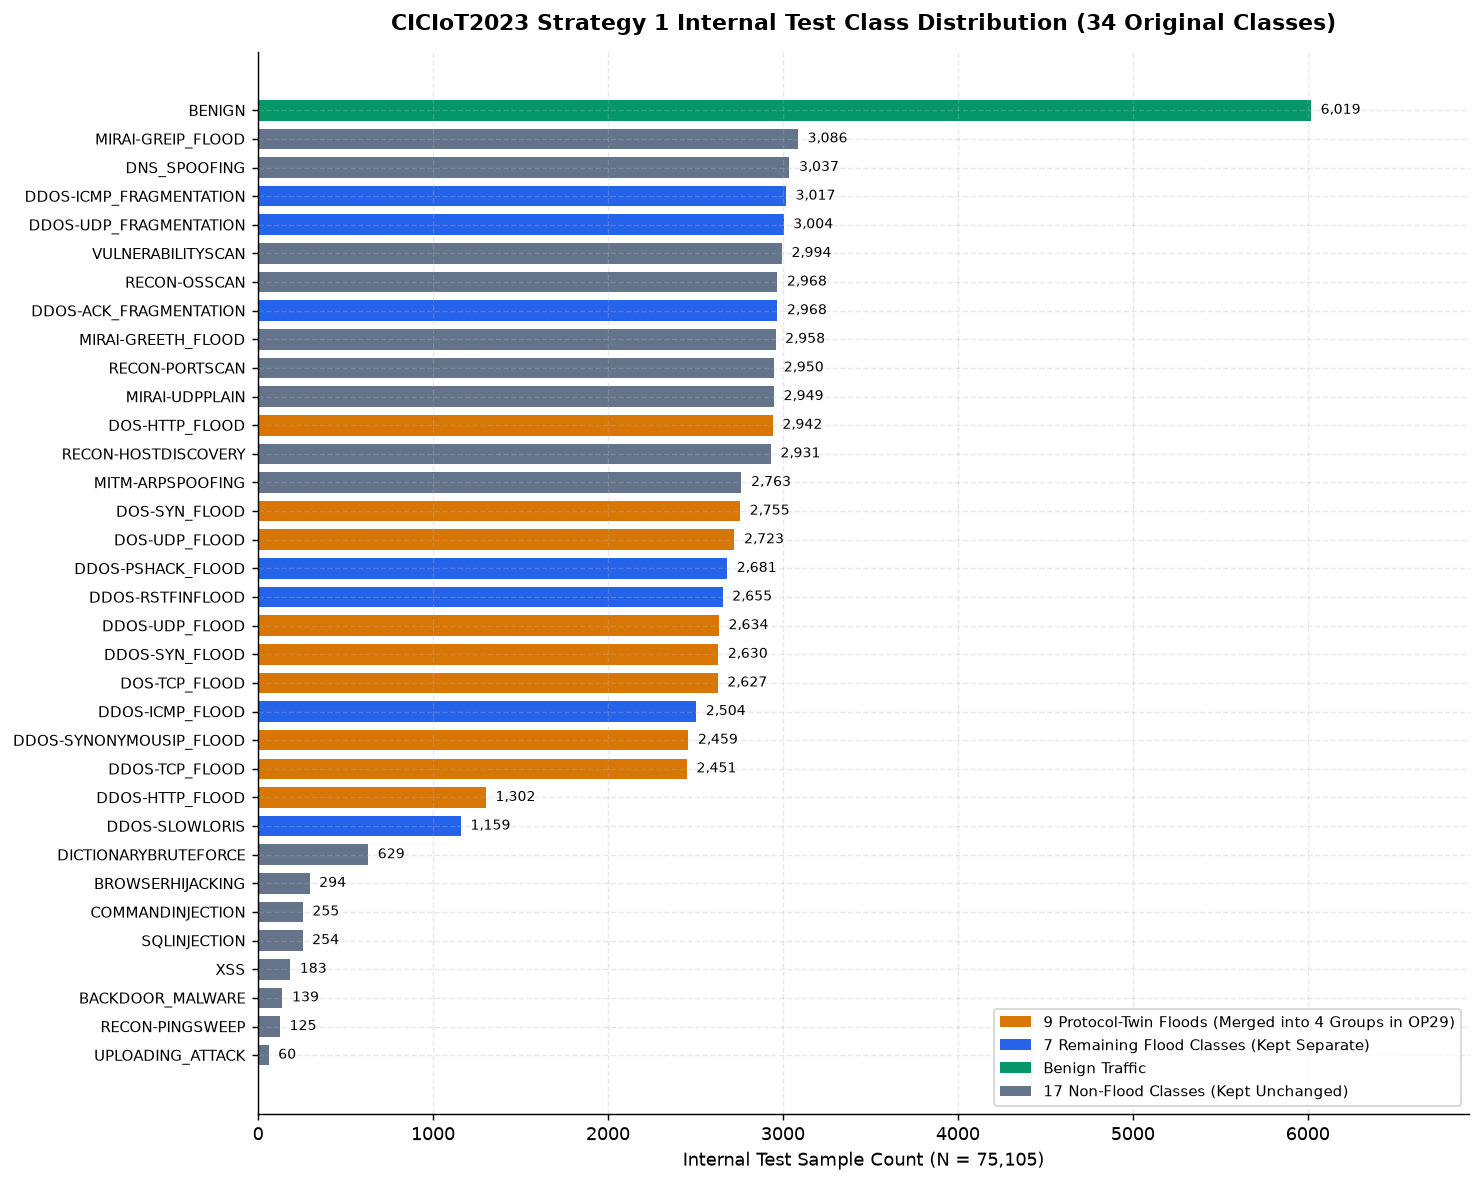

In [4]:
# Standalone Matplotlib Figure: Original 34-Class Internal Test Support Distribution
fig, ax = plt.subplots(figsize=(11.5, 9.2))
role_colors = {
    "Twin Flood (Merged in OP29)": "#D97706",
    "Other Flood (Unmerged)": "#2563EB",
    "Benign": "#059669",
}
bar_colors = [role_colors.get(r, "#64748B") for r in df_dist["role"]]
y_pos = np.arange(len(df_dist))

ax.barh(y_pos, df_dist["test_support"], color=bar_colors, height=0.72)
ax.set_yticks(y_pos)
ax.set_yticklabels(df_dist["class"], fontsize=8.2)
ax.set_xlabel("Internal Test Sample Count (N = 75,105)", fontsize=10)
ax.set_title("CICIoT2023 Strategy 1 Internal Test Class Distribution (34 Original Classes)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlim(0, df_dist["test_support"].max() * 1.15)

for yi, cnt in zip(y_pos, df_dist["test_support"]):
    ax.text(cnt + 55, yi, f"{cnt:,}", va="center", ha="left", fontsize=7.5)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="#D97706", label="9 Protocol-Twin Floods (Merged into 4 Groups in OP29)"),
    Patch(facecolor="#2563EB", label="7 Remaining Flood Classes (Kept Separate)"),
    Patch(facecolor="#059669", label="Benign Traffic"),
    Patch(facecolor="#64748B", label="17 Non-Flood Classes (Kept Unchanged)"),
]
ax.legend(handles=legend_handles, loc="lower right", fontsize=8.5, frameon=True)
plt.tight_layout()
plt.show()


## Section 3: Merged-Flood Operational Taxonomy (`OP29_MERGED_FLOOD` & `OP30` Sensitivity)

Auditing E4's 34-class test performance shows that unmerged Flood classes outside the `DDoS`/`DoS` twins (`DDOS-RSTFINFLOOD`, `DDOS-ICMP_FLOOD`, `DDOS-PSHACK_FLOOD`, `DDOS-ACK_FRAGMENTATION`, `DDOS-ICMP_FRAGMENTATION`, `DDOS-UDP_FRAGMENTATION`, and `DDOS-SLOWLORIS`) already achieve **0.933 to 0.9998 F1**. Confusion concentrates almost exclusively within four protocol-equivalent groups:

1. **SYN group (`FLOOD_SYN`)**:
   `DDOS-SYN_FLOOD`, `DOS-SYN_FLOOD`, `DDOS-SYNONYMOUSIP_FLOOD` -> `FLOOD_SYN`
2. **TCP group (`FLOOD_TCP`)**:
   `DDOS-TCP_FLOOD`, `DOS-TCP_FLOOD` -> `FLOOD_TCP`
3. **UDP group (`FLOOD_UDP`)**:
   `DDOS-UDP_FLOOD`, `DOS-UDP_FLOOD` -> `FLOOD_UDP`
4. **HTTP group (`FLOOD_HTTP`)**:
   `DDOS-HTTP_FLOOD`, `DOS-HTTP_FLOOD` -> `FLOOD_HTTP`

### Special Caveat on `DDOS-SYNONYMOUSIP_FLOOD`
In CICIoT2023, `DDOS-SYNONYMOUSIP_FLOOD` is a TCP SYN flood where spoofed packets reuse identical source and destination IP addresses (`src_ip == dst_ip`). At a perimeter router or firewall with access to **raw L3 IP headers**, a trivial stateless header ACL (`src_ip == dst_ip`) could separate `SYNONYMOUSIP` from generic TCP SYN floods. However, because the **39 exported CSV features contain no IP headers**, `DDOS-SYNONYMOUSIP_FLOOD` exhibits identical median SYN flags (`syn_flag_number = 1.0`, `syn_count = 100.0`, `Tot size = 60.0`) and shares **3,072 exact Train feature-vector hashes** with `{DDOS-SYN_FLOOD, DOS-SYN_FLOOD}`. If `SYNONYMOUSIP` is left unmerged (`OP30_STRICT_4_PAIR`), **2,321 SYN-family flows** still leak out of the SYN pair (`56.90%` retention vs. `99.62%` in `OP29`). Therefore, we evaluate **both** `OP30` and `OP29` side by side while documenting this L3 header caveat explicitly.


In [5]:
# Inspect frozen taxonomy JSON map and validate programmatic mapping bijection
with open(RESULTS_DIR / "merged_flood_taxonomy_map.json", "r") as f:
    tax_json = json.load(f)

classes_29, idx_map_29, proj_29, dict_29 = build_operational_mapping(OP29_MERGE_GROUPS)
classes_30, idx_map_30, proj_30, dict_30 = build_operational_mapping(OP30_MERGE_GROUPS)

assert classes_29 == tax_json["classes_29"]
assert dict_29 == tax_json["old_to_new_34_to_29"]
assert len(classes_30) == 30 and len(classes_29) == 29
assert len(set(dict_29.keys())) == 34 and len(set(dict_29.values())) == 29
assert len(set(dict_30.keys())) == 34 and len(set(dict_30.values())) == 30

mapping_table = pd.DataFrame([
    {
        "Merged OP29 Target": grp,
        "Source CICIoT2023 Classes (ORIG34)": ", ".join(members),
        "Merged Count": len(members),
        "Shared Protocol / Operational Mitigation Role": {
            "FLOOD_SYN": "TCP SYN queue saturation (SYN Cookies / embryonic limit; L3 src==dst ACL if IP header available)",
            "FLOOD_TCP": "Volumetric L4 TCP flood (FlowSpec rate-limit / stateful TCP scrub)",
            "FLOOD_UDP": "Volumetric L4 UDP flood (UDP ingress policing / QoS rate-limit)",
            "FLOOD_HTTP": "L7 HTTP request flood (WAF request throttle / HTTP challenge)",
        }[grp],
    }
    for grp, members in OP29_MERGE_GROUPS.items()
])
display(mapping_table)
print(f"Verified 34 -> 30 mapping ({len(classes_30)} classes) and 34 -> 29 mapping ({len(classes_29)} classes). Unmerged classes retained identically: {34 - 9}.")


,Merged OP29 Target,Source CICIoT2023 Classes (ORIG34),Merged Count,Shared Protocol / Operational Mitigation Role
0,FLOOD_SYN,"DDOS-SYN_FLOOD, DOS-SYN_FLOOD, DDOS-SYNONYMOUS...",3,TCP SYN queue saturation (SYN Cookies / embryo...
1,FLOOD_TCP,"DDOS-TCP_FLOOD, DOS-TCP_FLOOD",2,Volumetric L4 TCP flood (FlowSpec rate-limit /...
2,FLOOD_UDP,"DDOS-UDP_FLOOD, DOS-UDP_FLOOD",2,Volumetric L4 UDP flood (UDP ingress policing ...
3,FLOOD_HTTP,"DDOS-HTTP_FLOOD, DOS-HTTP_FLOOD",2,L7 HTTP request flood (WAF request throttle / ...


Verified 34 -> 30 mapping (30 classes) and 34 -> 29 mapping (29 classes). Unmerged classes retained identically: 25.


## Section 4: Evaluation Methodology

We compare three label taxonomies across the **exact same frozen E4 predictions and identical Internal Test population (`N = 75,105`)**:
1. **`ORIG34`**: Standard 34-class academic CICIoT2023 classification target.
2. **`OP30_STRICT_4_PAIR`**: Sensitivity check collapsing only the 4 literal `DDoS`/`DoS` pairs while keeping `DDOS-SYNONYMOUSIP_FLOOD` separate (`30` classes).
3. **`OP29_MERGED_FLOOD`**: Operational mitigation taxonomy merging all four twin groups, including `DDOS-SYNONYMOUSIP_FLOOD` into `FLOOD_SYN` (`29` classes).

### Strict Post-Hoc Evaluation Protocol
- **No model retraining**: We load the frozen Track 2 checkpoint `e4_lgbm_leaves63_sqrt.joblib` read-only.
- **No new split & no test tuning**: We reuse Track 1's verified zero-overlap Strategy 1 Internal Test split (`N = 75,105`) scaled by `preprocessor_strategy1.joblib`.
- **Exact label projection**: Both true labels $y_{\text{test}}^{(34)}$ and E4's frozen predicted labels $\hat{y}_{\text{test}}^{(34)}$ are deterministically mapped through $M_{34 \to K}$ (and checked against probability pooling $\arg\max_G \sum_{c \in G} P_{34}(c \mid x)$). Every cell in the merged $K \times K$ confusion matrix equals the exact block sum of E4's original $34 \times 34$ confusion matrix.


In [6]:
# Load frozen E4 model and generate deterministic Internal Test predictions (no training, no test tuning)
e4_model = joblib.load(HIER_MODELS_DIR / "e4_lgbm_leaves63_sqrt.joblib")
X_test = splits["test"]["X"]
y_prob_34 = e4_model.predict_proba(X_test)
y_pred_34 = np.argmax(y_prob_34, axis=1).astype(np.int64)

# Recompute all three taxonomies cleanly on identical Test samples
def eval_posthoc(tax_name, y_true_k, y_pred_k, y_prob_k, cls_names):
    m = evaluate_predictions_v2(
        y_true=y_true_k,
        y_pred=y_pred_k,
        y_prob=y_prob_k,
        class_names=cls_names,
    )
    rep = m["per_class_report"]
    merged_keys = [c for c in cls_names if c in set(FLOOD_CLASSES) or c.startswith("FLOOD_")]
    flood_macro_f1 = float(np.mean([rep[c]["f1-score"] for c in merged_keys]))
    nonflood_macro_f1 = float(np.mean([rep[c]["f1-score"] for c in NON_FLOOD_CLASSES]))
    return {
        "Taxonomy": tax_name,
        "Classes": len(cls_names),
        "AccuracyExactPct": float(m["accuracy"] * 100.0),
        "Accuracy": round(m["accuracy"], 5),
        "Macro-F1": round(m["macro_f1"], 5),
        "Weighted-F1": round(m["weighted_f1"], 5),
        "MCC": round(m["mcc"], 5),
        "Flood Macro-F1": round(flood_macro_f1, 5),
        "Non-Flood Macro-F1": round(nonflood_macro_f1, 5),
    }, m

# Project probabilities cleanly
y_prob_30 = y_prob_34 @ proj_30
y_prob_29 = y_prob_34 @ proj_29

row_34, res_34 = eval_posthoc("ORIG34", y_test_34, y_pred_34, y_prob_34, THIRTY_FOUR_CLASSES)
row_30, res_30 = eval_posthoc("OP30_STRICT_4_PAIR", idx_map_30[y_test_34], idx_map_30[y_pred_34], y_prob_30, classes_30)
row_29, res_29 = eval_posthoc("OP29_MERGED_FLOOD", idx_map_29[y_test_34], idx_map_29[y_pred_34], y_prob_29, classes_29)

# Verify exact parity against saved historical files and collapsed confusion matrices
df_saved_summary = pd.read_csv(RESULTS_DIR / "merged_flood_e4_summary.csv")
df_saved_final = pd.read_csv(RESULTS_DIR / "final_comparison_test.csv")
cm34_saved = np.load(CM_DIR / "cm_E4_Improved_Flat34_E4_LGBM_Leaves63_Sqrt_test.npy")
cm29_saved = np.load(CM_DIR / "cm_E4_merged_flood_29_test.npy")

assert np.array_equal(res_34["confusion_matrix"], cm34_saved), "ORIG34 confusion matrix parity mismatch!"
assert np.array_equal(res_29["confusion_matrix"], cm29_saved), "OP29 confusion matrix parity mismatch!"
assert np.array_equal(res_29["confusion_matrix"], (proj_29.T @ cm34_saved @ proj_29).astype(np.int64)), "Block-collapsed CM mismatch!"

e4_orig_ref = df_saved_final[df_saved_final["architecture"].str.startswith("E4_Improved_Flat34")].iloc[0]
assert abs(row_34["Accuracy"] - float(e4_orig_ref["accuracy"])) < 1e-5
assert abs(row_34["Macro-F1"] - float(e4_orig_ref["macro_f1"])) < 1e-5
assert abs(row_34["MCC"] - float(e4_orig_ref["mcc"])) < 1e-5

for tax_id, row_dict in [
    ("ORIG34", row_34),
    ("OP30_STRICT_4_PAIR", row_30),
    ("OP29_MERGED_FLOOD", row_29),
]:
    saved_match = df_saved_summary[
        (df_saved_summary["split"] == "test")
        & (df_saved_summary["taxonomy"] == tax_id)
        & (df_saved_summary["inference_mode"].isin(["native_34", "label_mapped"]))
    ].iloc[0]
    assert abs(row_dict["Accuracy"] - float(saved_match["accuracy"])) < 1e-5
    assert abs(row_dict["Macro-F1"] - float(saved_match["macro_f1"])) < 1e-5
    assert abs(row_dict["MCC"] - float(saved_match["mcc"])) < 1e-5
    assert abs(row_dict["Flood Macro-F1"] - float(saved_match["flood_macro_f1"])) < 1e-5
    assert abs(row_dict["Non-Flood Macro-F1"] - float(saved_match["non_flood_macro_f1"])) < 1e-5

print("All assertions passed: frozen E4 predictions on N = 75,105 match saved CSVs & CMs bit-for-bit.")


All assertions passed: frozen E4 predictions on N = 75,105 match saved CSVs & CMs bit-for-bit.


## Section 5: Quantitative Results

Every number in the comparison table below is verified directly against `merged_flood_e4_summary.csv`, `final_comparison_test.csv`, and live post-hoc remapping assertions on `N = 75,105` Internal Test samples. Notice that **Non-Flood Macro-F1 (`0.47885`) remains strictly identical** across all three views—confirming zero distortion to non-flood, benign, or minority attack classes.


In [7]:
df_comp = pd.DataFrame([row_34, row_30, row_29])
df_comp["Accuracy (%)"] = df_comp["AccuracyExactPct"].map(lambda v: f"{v:.2f}%")
display(df_comp[["Taxonomy", "Classes", "Accuracy (%)", "Accuracy", "Macro-F1", "MCC", "Flood Macro-F1", "Non-Flood Macro-F1", "Weighted-F1"]])

# Load per-class test results for both ORIG34 and OP29
df_per_class = pd.read_csv(RESULTS_DIR / "merged_flood_e4_per_class_test.csv")
print(f"Loaded per-class Test F1 table ({len(df_per_class)} rows: 34 ORIG34 + 29 OP29).")


,Taxonomy,Classes,Accuracy (%),Accuracy,Macro-F1,MCC,Flood Macro-F1,Non-Flood Macro-F1,Weighted-F1
0,ORIG34,34,75.37%,0.75366,0.63523,0.74402,0.79603,0.47885,0.74721
1,OP30_STRICT_4_PAIR,30,81.69%,0.81691,0.66421,0.80834,0.92206,0.47885,0.81366
2,OP29_MERGED_FLOOD,29,85.81%,0.85805,0.68082,0.85038,0.98931,0.47885,0.85341


Loaded per-class Test F1 table (63 rows: 34 ORIG34 + 29 OP29).


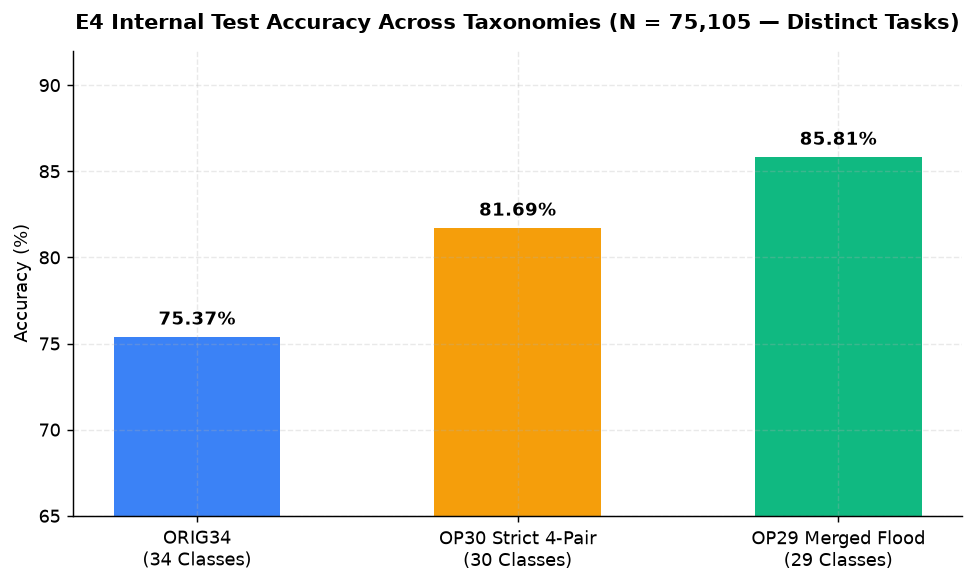

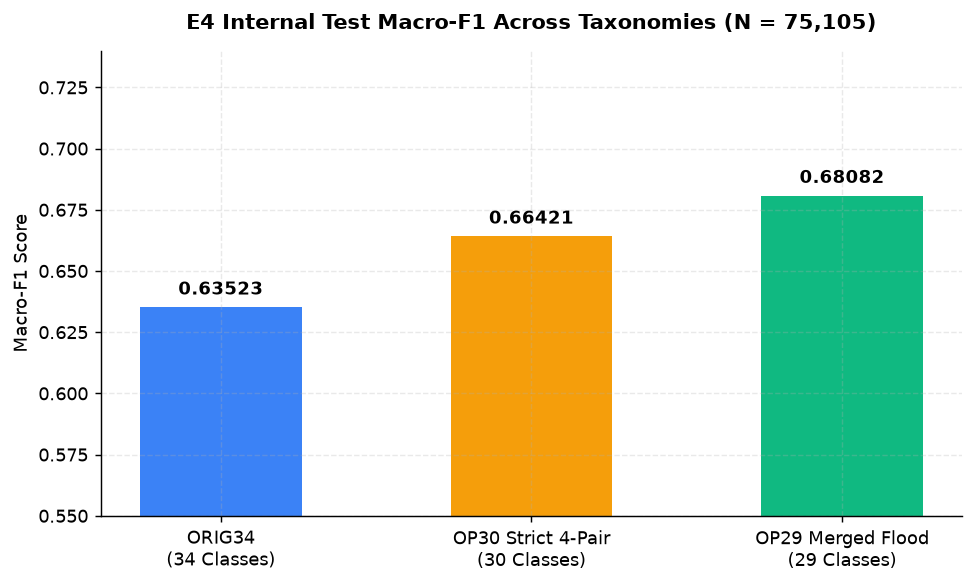

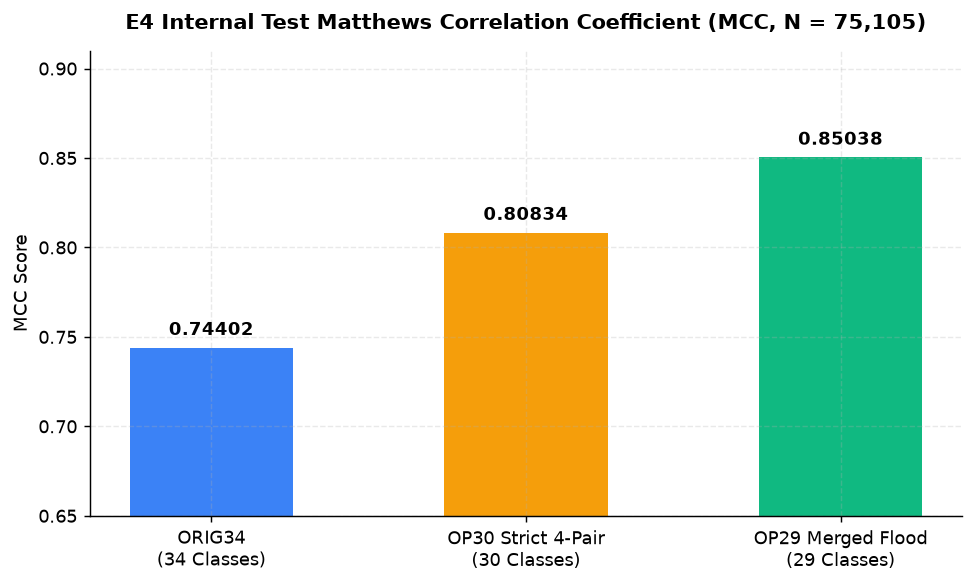

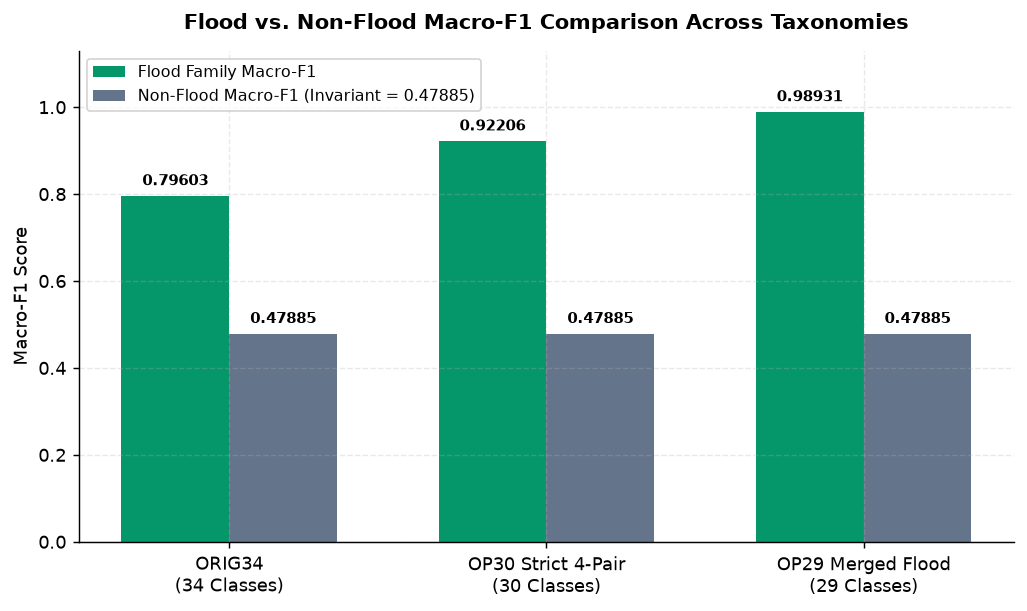

In [8]:
# Helper for clean single-metric comparison bar charts (one standalone figure per metric)
tax_labels = ["ORIG34\n(34 Classes)", "OP30 Strict 4-Pair\n(30 Classes)", "OP29 Merged Flood\n(29 Classes)"]
tax_colors = ["#3B82F6", "#F59E0B", "#10B981"]

def plot_metric_figure(values, title, ylabel, ylim, fmt):
    fig, ax = plt.subplots(figsize=(7.6, 4.6))
    x = np.arange(len(tax_labels))
    bars = ax.bar(x, values, color=tax_colors, width=0.52)
    ax.set_xticks(x)
    ax.set_xticklabels(tax_labels, fontsize=9.8)
    ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=11.5, fontweight="bold", pad=12)
    for bar, v in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            v + (ylim[1] - ylim[0]) * 0.018,
            fmt.format(v),
            ha="center",
            va="bottom",
            fontsize=9.8,
            fontweight="bold",
        )
    plt.tight_layout()
    plt.show()

# Figure 1: Accuracy Comparison
plot_metric_figure(
    list(df_comp["AccuracyExactPct"]),
    title="E4 Internal Test Accuracy Across Taxonomies (N = 75,105 — Distinct Tasks)",
    ylabel="Accuracy (%)",
    ylim=(65, 92),
    fmt="{:.2f}%",
)

# Figure 2: Macro-F1 Comparison
plot_metric_figure(
    list(df_comp["Macro-F1"]),
    title="E4 Internal Test Macro-F1 Across Taxonomies (N = 75,105)",
    ylabel="Macro-F1 Score",
    ylim=(0.55, 0.74),
    fmt="{:.5f}",
)

# Figure 3: MCC Comparison
plot_metric_figure(
    list(df_comp["MCC"]),
    title="E4 Internal Test Matthews Correlation Coefficient (MCC, N = 75,105)",
    ylabel="MCC Score",
    ylim=(0.65, 0.91),
    fmt="{:.5f}",
)

# Figure 4: Flood Macro-F1 Comparison (vs Invariant Non-Flood Macro-F1 Reference)
fig, ax = plt.subplots(figsize=(8.0, 4.8))
x = np.arange(len(tax_labels))
w = 0.34
b_flood = ax.bar(x - w / 2, df_comp["Flood Macro-F1"], width=w, color="#059669", label="Flood Family Macro-F1")
b_nonflood = ax.bar(x + w / 2, df_comp["Non-Flood Macro-F1"], width=w, color="#64748B", label="Non-Flood Macro-F1 (Invariant = 0.47885)")
ax.set_xticks(x)
ax.set_xticklabels(tax_labels, fontsize=9.8)
ax.set_ylim(0, 1.13)
ax.set_ylabel("Macro-F1 Score", fontsize=10)
ax.set_title("Flood vs. Non-Flood Macro-F1 Comparison Across Taxonomies", fontsize=11.5, fontweight="bold", pad=12)
ax.legend(loc="upper left", fontsize=8.8, frameon=True)
for bars in (b_flood, b_nonflood):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2.0, h + 0.016, f"{h:.5f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
plt.tight_layout()
plt.show()


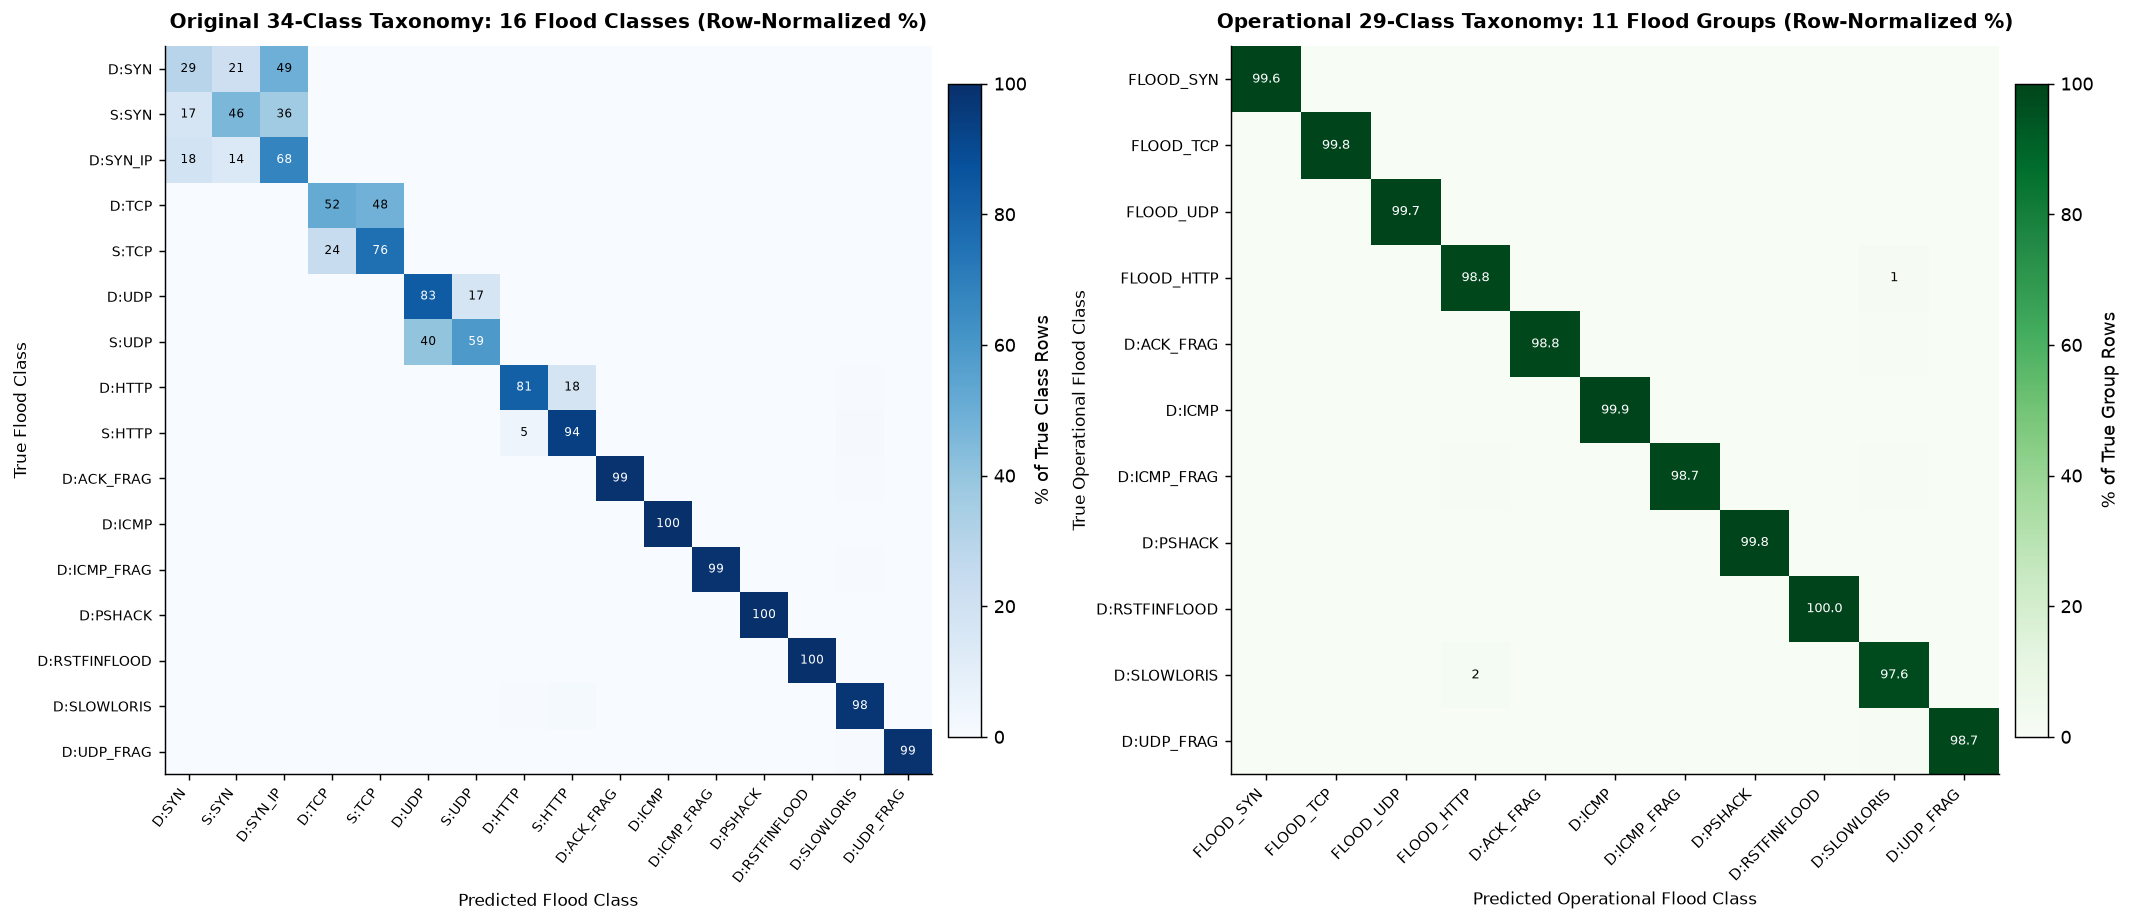

In [9]:
# Figure 5: Original (16 Flood) vs. Merged (11 Operational Flood) Row-Normalized Confusion Matrices
# Focuses strictly on the Flood subset so every class label and percentage is legible without seaborn.
orig_flood_order = [
    "DDOS-SYN_FLOOD", "DOS-SYN_FLOOD", "DDOS-SYNONYMOUSIP_FLOOD",
    "DDOS-TCP_FLOOD", "DOS-TCP_FLOOD",
    "DDOS-UDP_FLOOD", "DOS-UDP_FLOOD",
    "DDOS-HTTP_FLOOD", "DOS-HTTP_FLOOD",
    "DDOS-ACK_FRAGMENTATION", "DDOS-ICMP_FLOOD", "DDOS-ICMP_FRAGMENTATION",
    "DDOS-PSHACK_FLOOD", "DDOS-RSTFINFLOOD", "DDOS-SLOWLORIS", "DDOS-UDP_FRAGMENTATION",
]
merged_flood_order = [
    "FLOOD_SYN", "FLOOD_TCP", "FLOOD_UDP", "FLOOD_HTTP",
    "DDOS-ACK_FRAGMENTATION", "DDOS-ICMP_FLOOD", "DDOS-ICMP_FRAGMENTATION",
    "DDOS-PSHACK_FLOOD", "DDOS-RSTFINFLOOD", "DDOS-SLOWLORIS", "DDOS-UDP_FRAGMENTATION",
]

cm34_full = res_34["confusion_matrix"]
cm29_full = res_29["confusion_matrix"]
idx_34_flood = [THIRTY_FOUR_TO_IDX[c] for c in orig_flood_order]
c29_to_idx = {c: i for i, c in enumerate(classes_29)}
idx_29_flood = [c29_to_idx[c] for c in merged_flood_order]

sub34 = cm34_full[np.ix_(idx_34_flood, idx_34_flood)].astype(np.float64)
sub34_norm = sub34 / np.clip(cm34_full[idx_34_flood].sum(axis=1, keepdims=True), 1, None) * 100.0

sub29 = cm29_full[np.ix_(idx_29_flood, idx_29_flood)].astype(np.float64)
sub29_norm = sub29 / np.clip(cm29_full[idx_29_flood].sum(axis=1, keepdims=True), 1, None) * 100.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5, 7.2))

im1 = ax1.imshow(sub34_norm, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax1.set_title("Original 34-Class Taxonomy: 16 Flood Classes (Row-Normalized %)", fontsize=11, fontweight="bold", pad=10)
ax1.set_xticks(np.arange(len(orig_flood_order)))
ax1.set_yticks(np.arange(len(orig_flood_order)))
short34 = [c.replace("DDOS-", "D:").replace("DOS-", "S:").replace("_FLOOD", "").replace("FRAGMENTATION", "FRAG").replace("SYNONYMOUSIP", "SYN_IP") for c in orig_flood_order]
ax1.set_xticklabels(short34, rotation=52, ha="right", fontsize=7.6)
ax1.set_yticklabels(short34, fontsize=7.8)
ax1.set_xlabel("Predicted Flood Class", fontsize=9.5)
ax1.set_ylabel("True Flood Class", fontsize=9.5)
ax1.grid(False)
for r in range(sub34_norm.shape[0]):
    for c in range(sub34_norm.shape[1]):
        val = sub34_norm[r, c]
        if val >= 2.0:
            ax1.text(c, r, f"{val:.0f}", ha="center", va="center", fontsize=6.6, color=("white" if val > 55 else "black"))

im2 = ax2.imshow(sub29_norm, cmap="Greens", vmin=0, vmax=100, aspect="auto")
ax2.set_title("Operational 29-Class Taxonomy: 11 Flood Groups (Row-Normalized %)", fontsize=11, fontweight="bold", pad=10)
ax2.set_xticks(np.arange(len(merged_flood_order)))
ax2.set_yticks(np.arange(len(merged_flood_order)))
short29 = [c.replace("DDOS-", "D:").replace("_FLOOD", "").replace("FRAGMENTATION", "FRAG") for c in merged_flood_order]
ax2.set_xticklabels(short29, rotation=45, ha="right", fontsize=8.3)
ax2.set_yticklabels(short29, fontsize=8.3)
ax2.set_xlabel("Predicted Operational Flood Class", fontsize=9.5)
ax2.set_ylabel("True Operational Flood Class", fontsize=9.5)
ax2.grid(False)
for r in range(sub29_norm.shape[0]):
    for c in range(sub29_norm.shape[1]):
        val = sub29_norm[r, c]
        if val >= 1.0:
            ax2.text(c, r, f"{val:.1f}" if r == c else f"{val:.0f}", ha="center", va="center", fontsize=7.2, color=("white" if val > 55 else "black"))

fig.colorbar(im1, ax=ax1, fraction=0.04, pad=0.02, label="% of True Class Rows")
fig.colorbar(im2, ax=ax2, fraction=0.04, pad=0.02, label="% of True Group Rows")
plt.tight_layout()
plt.show()


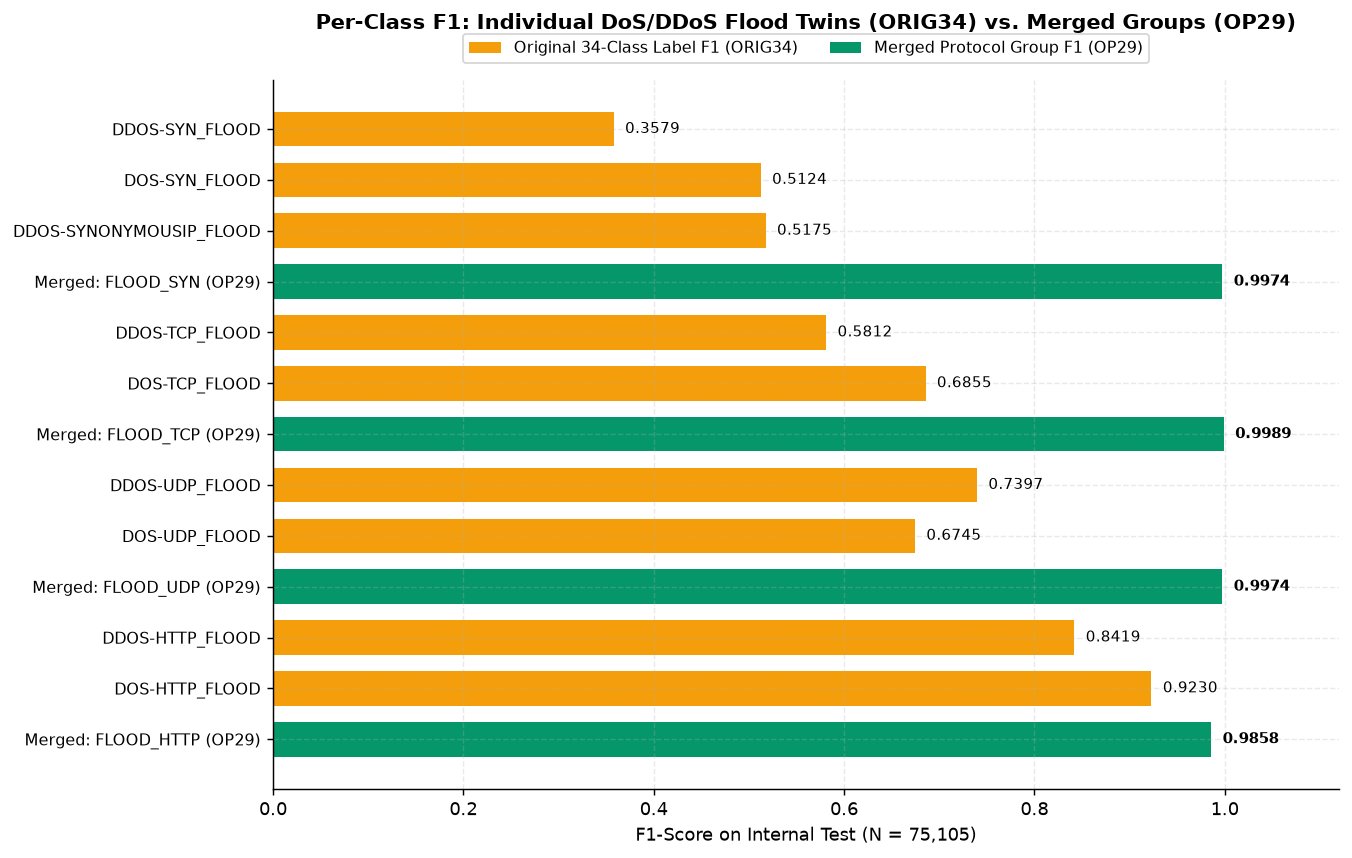

In [10]:
# Figure 6: Per-Class F1 Comparison Across the 4 Protocol-Twin Groups (Pre-Merge vs. Post-Merge)
pc34 = df_per_class[df_per_class["taxonomy"] == "ORIG34"].set_index("class")
pc29 = df_per_class[df_per_class["taxonomy"] == "OP29_MERGED_FLOOD"].set_index("class")

bars_spec = [
    ("DDOS-SYN_FLOOD", float(pc34.loc["DDOS-SYN_FLOOD", "f1"]), "#F59E0B"),
    ("DOS-SYN_FLOOD", float(pc34.loc["DOS-SYN_FLOOD", "f1"]), "#F59E0B"),
    ("DDOS-SYNONYMOUSIP_FLOOD", float(pc34.loc["DDOS-SYNONYMOUSIP_FLOOD", "f1"]), "#F59E0B"),
    ("Merged: FLOOD_SYN (OP29)", float(pc29.loc["FLOOD_SYN", "f1"]), "#059669"),
    ("DDOS-TCP_FLOOD", float(pc34.loc["DDOS-TCP_FLOOD", "f1"]), "#F59E0B"),
    ("DOS-TCP_FLOOD", float(pc34.loc["DOS-TCP_FLOOD", "f1"]), "#F59E0B"),
    ("Merged: FLOOD_TCP (OP29)", float(pc29.loc["FLOOD_TCP", "f1"]), "#059669"),
    ("DDOS-UDP_FLOOD", float(pc34.loc["DDOS-UDP_FLOOD", "f1"]), "#F59E0B"),
    ("DOS-UDP_FLOOD", float(pc34.loc["DOS-UDP_FLOOD", "f1"]), "#F59E0B"),
    ("Merged: FLOOD_UDP (OP29)", float(pc29.loc["FLOOD_UDP", "f1"]), "#059669"),
    ("DDOS-HTTP_FLOOD", float(pc34.loc["DDOS-HTTP_FLOOD", "f1"]), "#F59E0B"),
    ("DOS-HTTP_FLOOD", float(pc34.loc["DOS-HTTP_FLOOD", "f1"]), "#F59E0B"),
    ("Merged: FLOOD_HTTP (OP29)", float(pc29.loc["FLOOD_HTTP", "f1"]), "#059669"),
]

fig, ax = plt.subplots(figsize=(10.5, 6.7))
yp = np.arange(len(bars_spec))[::-1]
lbls = [s[0] for s in bars_spec]
vals = [s[1] for s in bars_spec]
cols = [s[2] for s in bars_spec]

ax.barh(yp, vals, color=cols, height=0.68)
ax.set_yticks(yp)
ax.set_yticklabels(lbls, fontsize=9.0)
ax.set_xlim(0, 1.12)
ax.set_xlabel("F1-Score on Internal Test (N = 75,105)", fontsize=10)
ax.set_title("Per-Class F1: Individual DoS/DDoS Flood Twins (ORIG34) vs. Merged Groups (OP29)", fontsize=11.5, fontweight="bold", pad=28)
for y_i, v_i, s_lbl in zip(yp, vals, lbls):
    weight = "bold" if s_lbl.startswith("Merged:") else "normal"
    ax.text(v_i + 0.012, y_i, f"{v_i:.4f}", va="center", ha="left", fontsize=8.4, fontweight=weight)

from matplotlib.patches import Patch
ax.legend(
    handles=[
        Patch(facecolor="#F59E0B", label="Original 34-Class Label F1 (ORIG34)"),
        Patch(facecolor="#059669", label="Merged Protocol Group F1 (OP29)"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.075),
    ncol=2,
    fontsize=8.8,
    frameon=True,
)
plt.tight_layout()
plt.show()


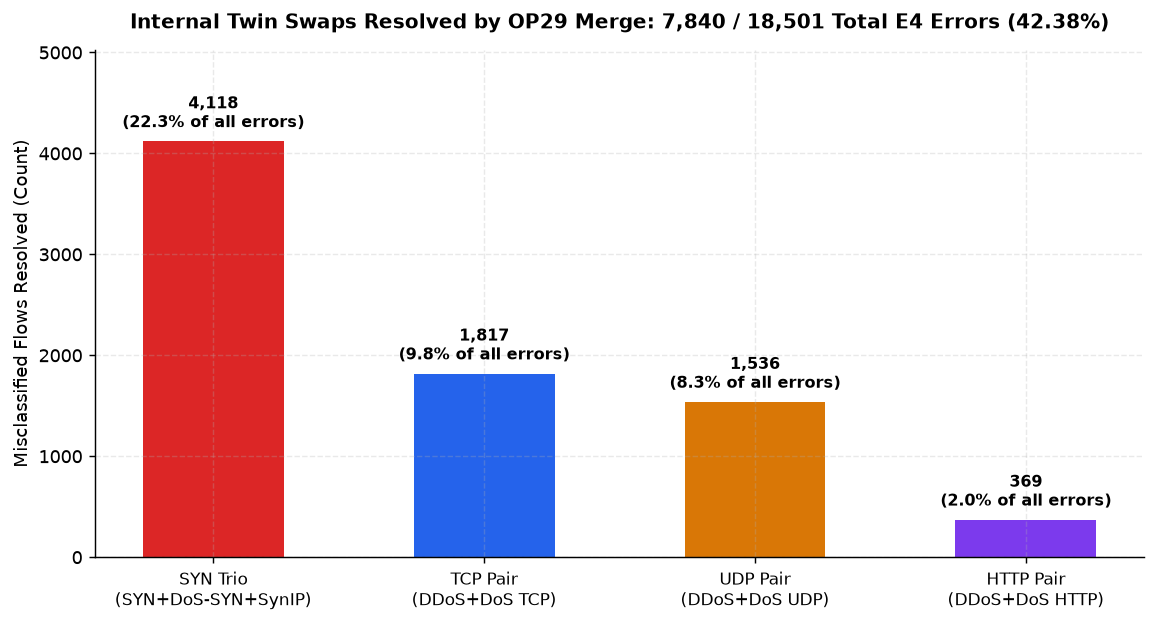

In [11]:
# Figure 7: The Four Flood Twin-Group Error Contributions (Swaps Resolved in OP29)
op29_audit = df_audit[df_audit["group"].isin(["SYN_TRIO (29-cls)", "TCP_PAIR", "UDP_PAIR", "HTTP_PAIR"])].copy()
op29_audit = op29_audit.sort_values("internal_twin_swaps", ascending=False).reset_index(drop=True)

total_orig_errors = int(cm34_full.sum() - np.trace(cm34_full))
swaps_resolved = int(op29_audit["internal_twin_swaps"].sum())
op29_audit["pct_of_all_e4_errors"] = 100.0 * op29_audit["internal_twin_swaps"] / total_orig_errors

fig, ax = plt.subplots(figsize=(9.0, 4.9))
gx = np.arange(len(op29_audit))
g_names = ["SYN Trio\n(SYN+DoS-SYN+SynIP)", "TCP Pair\n(DDoS+DoS TCP)", "UDP Pair\n(DDoS+DoS UDP)", "HTTP Pair\n(DDoS+DoS HTTP)"]
bars = ax.bar(gx, op29_audit["internal_twin_swaps"], color=["#DC2626", "#2563EB", "#D97706", "#7C3AED"], width=0.52)
ax.set_xticks(gx)
ax.set_xticklabels(g_names, fontsize=9.5)
ax.set_ylim(0, op29_audit["internal_twin_swaps"].max() * 1.22)
ax.set_ylabel("Misclassified Flows Resolved (Count)", fontsize=10)
ax.set_title(
    f"Internal Twin Swaps Resolved by OP29 Merge: {swaps_resolved:,} / {total_orig_errors:,} Total E4 Errors ({100.0*swaps_resolved/total_orig_errors:.2f}%)",
    fontsize=11.2,
    fontweight="bold",
    pad=12,
)
for bar, cnt, pct in zip(bars, op29_audit["internal_twin_swaps"], op29_audit["pct_of_all_e4_errors"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        cnt + 90,
        f"{cnt:,}\n({pct:.1f}% of all errors)",
        ha="center",
        va="bottom",
        fontsize=8.6,
        fontweight="bold",
    )
plt.tight_layout()
plt.show()


## Section 6: Error Analysis (`18,501` -> `10,661` Test Errors)

Here we quantify precisely how the error budget shifts under post-hoc taxonomy remapping and demonstrate **why merging collapses within-group swaps without altering E4's underlying classifier behavior**:
- Original E4 Test errors (`ORIG34`): **`18,501`** out of `75,105` samples (`24.63%` error rate).
- Errors resolved solely by merging the 4 Flood twin groups (`OP29`): **`7,840`** flows (`42.38%`, or approximately **`42.4%`**, of all original E4 errors).
- Remaining residual Test errors in `OP29`: **`10,661`** (`57.62%` of original errors—unchanged Non-Flood confusion, Benign/Attack boundary misses, and `110` cross-group/outside Flood errors).

**Core Principle**: E4's tree splits and probabilities did not improve on the original 34-class problem; rather, redefining the targets removes synthetic penalization for indistinguishable single-flow swaps.


In [12]:
err_34 = int(cm34_full.sum() - np.trace(cm34_full))
err_30 = int(res_30["confusion_matrix"].sum() - np.trace(res_30["confusion_matrix"]))
err_29 = int(cm29_full.sum() - np.trace(cm29_full))

resolved_29 = err_34 - err_29
pct_resolved_29 = 100.0 * resolved_29 / err_34

assert err_34 == 18501, f"Expected 18,501 errors, got {err_34}"
assert resolved_29 == 7840, f"Expected 7,840 resolved swaps, got {resolved_29}"
assert abs(pct_resolved_29 - 42.376) < 0.01

print(f"Original E4 Test Errors (ORIG34)  : {err_34:,} / {len(y_test_34):,} ({100.0*err_34/len(y_test_34):.2f}%)")
print(f"OP30 Strict 4-Pair Errors         : {err_30:,} (resolved {err_34 - err_30:,} swaps; {100.0*(err_34-err_30)/err_34:.2f}%)")
print(f"OP29 Merged-Flood Errors          : {err_29:,} (resolved {resolved_29:,} swaps; {pct_resolved_29:.2f}% / ~42.4%)")
print("\nGroup-by-group swap breakdown inside resolved 7,840 errors:")
for _, r in op29_audit.iterrows():
    share_of_resolved = 100.0 * r["internal_twin_swaps"] / resolved_29
    print(f"  - {r['group']:<20}: {int(r['internal_twin_swaps']):5,} swaps ({share_of_resolved:5.2f}% of resolved | {r['pct_of_all_e4_errors']:5.2f}% of all E4 errors)")


Original E4 Test Errors (ORIG34)  : 18,501 / 75,105 (24.63%)
OP30 Strict 4-Pair Errors         : 13,751 (resolved 4,750 swaps; 25.67%)
OP29 Merged-Flood Errors          : 10,661 (resolved 7,840 swaps; 42.38% / ~42.4%)

Group-by-group swap breakdown inside resolved 7,840 errors:
  - SYN_TRIO (29-cls)   : 4,118 swaps (52.53% of resolved | 22.26% of all E4 errors)
  - TCP_PAIR            : 1,817 swaps (23.18% of resolved |  9.82% of all E4 errors)
  - UDP_PAIR            : 1,536 swaps (19.59% of resolved |  8.30% of all E4 errors)
  - HTTP_PAIR           :   369 swaps ( 4.71% of resolved |  1.99% of all E4 errors)


## Section 7: Operational Interpretation

From an operational SOC or edge firewall perspective, the contrast between `ORIG34` (`75.37%`) and `OP29` (`85.81%`, `0.98931` Flood Macro-F1) clarifies how ML outputs should drive automated enforcement:

| Operational Prediction (`OP29`) | Protocol Family | Actionable Firewall / Traffic-Management Policy | What Requires External Host Telemetry? |
| :--- | :--- | :--- | :--- |
| **`FLOOD_SYN`** | TCP SYN (`L4`) | Enable SYN Cookies, tighten embryonic connection backlog/rate limits; add stateless `src_ip == dst_ip` L3 ACL if router telemetry indicates self-spoofed packets | Single-host DoS vs. multi-host DDoS botnet scope |
| **`FLOOD_TCP`** | Volumetric TCP (`L4`) | Trigger BGP FlowSpec rate-limiting, per-tuple TCP policing, or upstream scrub | Identifying top offending source prefixes / ASNs |
| **`FLOOD_UDP`** | Volumetric UDP (`L4`) | Apply ingress UDP rate-limiting and QoS bandwidth policing | Distinguishing single-host UDP sender vs. reflection/botnet fan-in |
| **`FLOOD_HTTP`** | HTTP Flood (`L7`) | Route through reverse-proxy rate throttling, CAPTCHA/JS challenge, or WAF connection limits | Attributing distributed bot IPs vs. single aggressive client |

### Separation of Responsibilities in Production
1. **Inline Tabular IDS (`E4` -> `OP29`)**: Maps 39 packet/flow statistics into crisp protocol-level mitigation classes (`>98.5%` F1 across all four merged flood groups) for firewall or traffic-management rule selection.
2. **Upstream Telemetry / Forensic SIEM**: Collects source IP, destination IP, flow keys, distinct attacker-IP counts, traffic fan-in distributions, and temporal aggregation over NetFlow/sFlow/IPFIX to resolve whether a detected flood is single-source DoS or distributed DDoS.

**Boundary on Evidence**: This offline classification study quantifies label-consistency improvements under `OP29`; it **does not prove downstream firewall drop efficacy or packet-level mitigation performance** in live networks, which require testbed replay validation.


## Section 8: Limitations and Caveats

1. **`OP29` and `ORIG34` are distinct classification tasks**: Comparing `85.81%` Accuracy on 29 classes against `75.37%` Accuracy on 34 classes across identical samples reflects target-space coarsening—never an apples-to-apples beat over 34-class baselines.
2. **No improvement to underlying model capability**: Frozen E4 learned identical decision trees; only the evaluation label granularity changed.
3. **Reduced diagnostic granularity**: Collapsing `DoS` and `DDoS` removes single-source vs. distributed attribution from the ML classifier's output, shifting host-scope determination onto upstream telemetry.
4. **Possible packet-header separation for `DDOS-SYNONYMOUSIP_FLOOD`**: A router or packet broker inspecting raw IP headers can isolate `src_ip == dst_ip` packets before tabular feature extraction, even though the exported 39 CSV features omit IP fields.
5. **Dataset and partition specificity**: Quantitative metrics reflect CICIoT2023's stratified working subset (`sample_stratified.csv`) and Track 1's Strategy 1 Internal Test partition (`N = 75,105`). Furthermore, Non-Flood (`0.47885` Macro-F1) and rare Web/Recon classes (`0.21957` Minority F1) remain unaffected and challenging in 39-feature tabular flow space.
6. **Operational validation prerequisite**: Before enabling automated mitigation playbooks (`SYN Cookies`, FlowSpec drops, WAF rate limits) based on `OP29` predictions, production threshold calibration and benign false-positive impact (`21.37%` single-flow Benign FPR on E4) must be validated with stateful flow aggregation in staging traffic.


## Section 9: Conclusion

1. **Retain `ORIG34` for Research Benchmarking**: The original 34-class taxonomy (`75.37%` E4 Test Acc, `0.63523` Macro-F1, `0.74402` MCC) preserves direct comparability with Track 1 and published CICIoT2023 studies, and rigorously exposes where single-flow tabular models fail (`42.4%` error ceiling on IP-stripped DoS/DDoS twins).
2. **Adopt `OP29_MERGED_FLOOD` for Protocol-Level Operational Mitigation**: Merging the four protocol-equivalent twin groups (`FLOOD_SYN`, `FLOOD_TCP`, `FLOOD_UDP`, `FLOOD_HTTP`) yields **`0.98931` Flood Macro-F1** (`85.81%` Test Accuracy, `0.85038` MCC) on the same frozen E4 outputs, aligning model alerts with realistic L4/L7 mitigation policies.
3. **Host-Level Telemetry Is Required for DoS vs. DDoS Attribution**: Separating single-origin DoS from distributed DDoS requires source/destination IP keys, host cardinality, and temporal aggregation that lie outside the 39 CICIoT2023 tabular features.
4. **Complementary Dual-Taxonomy Reporting**: Both taxonomies should be preserved—`ORIG34` to benchmark classifier fidelity honestly against academic literature, and `OP29` to communicate protocol-level remediation capability in SOC operations (as integrated toggleably in [`track2_ids_engineering/scripts/demo_app.py`](../track2_ids_engineering/scripts/demo_app.py)).
